<a href="https://colab.research.google.com/github/JoDepoy-pixel/CompNeuro2026/blob/main/Homework4_APPM5370.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<>:114: SyntaxWarning: invalid escape sequence '\s'
<>:114: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2491/2781915807.py:114: SyntaxWarning: invalid escape sequence '\s'
  ax.set_title(f'Ocular Dominance Pattern on Ring ($\sigma_e = 1.0, \sigma_i = {sigma_i}$)', fontsize=12, fontweight='bold')


          OCULAR DOMINANCE STRIPE SIMULATION RESULTS             

--- Results for sigma_i = 2.0 ---
  • Simulated Period (Mean ± Std over 20 trials) : 6.362 ± 0.282 sites
  • Analytical Period (2π / k*)                    : 6.536 sites
  • Best Discrete Ring Mode Period (Mode m=31)   : 6.452 sites

--- Results for sigma_i = 3.0 ---
  • Simulated Period (Mean ± Std over 20 trials) : 8.224 ± 0.296 sites
  • Analytical Period (2π / k*)                    : 8.478 sites
  • Best Discrete Ring Mode Period (Mode m=24)   : 8.333 sites



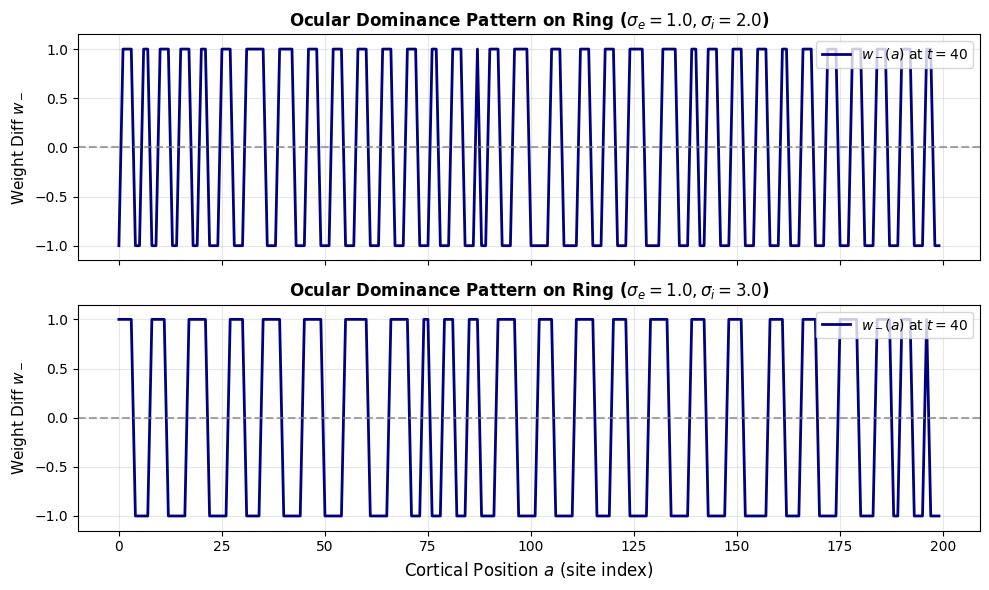

In [1]:
#Problem 1c
import numpy as np
import matplotlib.pyplot as plt

# Set seed for reproducibility across trials
np.random.seed(42)

# ==========================================
# 1. Simulation & Physics Parameters
# ==========================================
N = 200                    # Number of cortical sites on ring
sigma_e = 1.0              # Excitatory radius
sigma_i_list = [2.0, 3.0]  # Inhibitory radii to test[cite: 1]
dt = 0.02                  # Time step[cite: 1]
t_max = 40.0               # Maximum simulation time[cite: 1]
num_steps = int(t_max / dt)# Number of Euler steps
num_trials = 20            # Initial conditions per sigma_i[cite: 1]
init_std = 0.01            # Standard deviation for random initial w_minus[cite: 1]

# Spatial grid on ring with periodic distance
x = np.arange(N)
# Periodic distance on a ring of size N
dist = np.minimum(x, N - x)

# Fourier frequencies corresponding to discrete ring modes k = 2*pi*m / N
m = np.fft.fftfreq(N) * N  # Integer mode indices m = 0, 1, ..., N/2, -N/2+1, ...
k_discrete = 2 * np.pi * m / N

# Function to construct Mexican Hat Kernel on periodic ring
def get_kernel(s_e, s_i):
    # K(x) = exp(-x^2 / 2s_e^2) - (s_e / s_i) * exp(-x^2 / 2s_i^2)[cite: 1]
    K = np.exp(-dist**2 / (2 * s_e**2)) - (s_e / s_i) * np.exp(-dist**2 / (2 * s_i**2))
    return K

# Function to count right/left stripe pairs
def count_stripe_pairs(w_final):
    # Zero crossings of w_minus indicate boundaries between L/R ocular dominance stripes
    zero_crossings = np.where(np.diff(np.sign(w_final)))[0]
    num_crossings = len(zero_crossings)
    # Total stripe pairs = number of zero-crossings / 2
    num_pairs = num_crossings / 2.0
    return num_pairs

# Storage for final pattern plot
final_patterns = {}

print("=================================================================")
print("          OCULAR DOMINANCE STRIPE SIMULATION RESULTS             ")
print("=================================================================\n")

# ==========================================
# 2. Main Simulation Loop over sigma_i
# ==========================================
for sigma_i in sigma_i_list:
    # Build kernel and precompute FFT for fast convolution
    K = get_kernel(sigma_e, sigma_i)
    K_fft = np.fft.fft(K)

    # Analytical fastest-growing continuous wavenumber k_*[cite: 1]
    k_star_sq = (4.0 * np.log(sigma_i / sigma_e)) / (sigma_i**2 - sigma_e**2)
    k_star = np.sqrt(k_star_sq)
    period_analytical = (2 * np.pi) / k_star  # 2*pi / k_*[cite: 1]

    # Discrete mode on ring that maximizes K_fft
    K_fft_real = K_fft.real
    best_mode_idx = np.argmax(K_fft_real)
    m_best = abs(m[best_mode_idx])
    period_discrete_best = N / m_best if m_best > 0 else np.inf

    periods_simulated = []

    for trial in range(num_trials):
        # Initial condition: independent normal with std 0.01[cite: 1]
        w_minus = np.random.normal(0, init_std, size=N)

        # Forward Euler Integration loop[cite: 1]
        for step in range(num_steps):
            # Fast circular convolution via FFT: F^-1{ F{K} * F{w_minus} }
            conv = np.fft.ifft(K_fft * np.fft.fft(w_minus)).real

            # Forward Euler step[cite: 1]
            w_minus += dt * conv

            # Clip w_minus to [-1, 1] after each step[cite: 1]
            w_minus = np.clip(w_minus, -1.0, 1.0)

        # Record final pattern for trial 0
        if trial == 0:
            final_patterns[sigma_i] = w_minus.copy()

        # Measure period: N / (number of R/L stripe pairs)[cite: 1]
        n_pairs = count_stripe_pairs(w_minus)
        if n_pairs > 0:
            periods_simulated.append(N / n_pairs)

    mean_sim_period = np.mean(periods_simulated)
    std_sim_period = np.std(periods_simulated)

    # Print comparison table summary
    print(f"--- Results for sigma_i = {sigma_i} ---")
    print(f"  • Simulated Period (Mean ± Std over 20 trials) : {mean_sim_period:.3f} ± {std_sim_period:.3f} sites")
    print(f"  • Analytical Period (2π / k*)                    : {period_analytical:.3f} sites")
    print(f"  • Best Discrete Ring Mode Period (Mode m={int(m_best)})   : {period_discrete_best:.3f} sites\n")

# ==========================================
# 3. Plotting Final Patterns
# ==========================================
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

for ax, sigma_i in zip(axes, sigma_i_list):
    ax.plot(x, final_patterns[sigma_i], color='navy', lw=2, label=f'$w_-(a)$ at $t=40$')
    ax.axhline(0, color='gray', linestyle='--', alpha=0.7)
    ax.set_ylim(-1.15, 1.15)
    ax.set_ylabel('Weight Diff $w_-$', fontsize=11)
    ax.set_title(f'Ocular Dominance Pattern on Ring ($\sigma_e = 1.0, \sigma_i = {sigma_i}$)', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')

axes[1].set_xlabel('Cortical Position $a$ (site index)', fontsize=12)
plt.tight_layout()
plt.show()

<>:110: SyntaxWarning: invalid escape sequence '\l'
<>:111: SyntaxWarning: invalid escape sequence '\l'
<>:113: SyntaxWarning: invalid escape sequence '\l'
<>:114: SyntaxWarning: invalid escape sequence '\l'
<>:118: SyntaxWarning: invalid escape sequence '\P'
<>:118: SyntaxWarning: invalid escape sequence '\m'
<>:118: SyntaxWarning: invalid escape sequence '\s'
<>:118: SyntaxWarning: invalid escape sequence '\l'
<>:127: SyntaxWarning: invalid escape sequence '\l'
<>:128: SyntaxWarning: invalid escape sequence '\l'
<>:130: SyntaxWarning: invalid escape sequence '\l'
<>:110: SyntaxWarning: invalid escape sequence '\l'
<>:111: SyntaxWarning: invalid escape sequence '\l'
<>:113: SyntaxWarning: invalid escape sequence '\l'
<>:114: SyntaxWarning: invalid escape sequence '\l'
<>:118: SyntaxWarning: invalid escape sequence '\P'
<>:118: SyntaxWarning: invalid escape sequence '\m'
<>:118: SyntaxWarning: invalid escape sequence '\s'
<>:118: SyntaxWarning: invalid escape sequence '\l'
<>:127: Synt

Starting Euler-Maruyama Simulations...

λ = 0.0, θ = 0.5 | Acc: 0.5935, Mean Time: 0.5271 s
λ = 0.0, θ = 1.0 | Acc: 0.6870, Mean Time: 1.9834 s
λ = 0.0, θ = 1.5 | Acc: 0.7676, Mean Time: 4.0876 s
λ = 0.0, θ = 2.0 | Acc: 0.8406, Mean Time: 6.8278 s
λ = 0.0, θ = 2.5 | Acc: 0.8855, Mean Time: 9.6222 s
λ = 0.0, θ = 3.0 | Acc: 0.9190, Mean Time: 12.6628 s
λ = 0.0, θ = 3.5 | Acc: 0.9431, Mean Time: 15.4601 s
λ = 0.0, θ = 4.0 | Acc: 0.9643, Mean Time: 18.5239 s
λ = 0.2, θ = 0.5 | Acc: 0.6036, Mean Time: 0.5069 s
λ = 0.2, θ = 1.0 | Acc: 0.6839, Mean Time: 1.7256 s
λ = 0.2, θ = 1.5 | Acc: 0.7449, Mean Time: 3.2484 s
λ = 0.2, θ = 2.0 | Acc: 0.7741, Mean Time: 4.6289 s
λ = 0.2, θ = 2.5 | Acc: 0.8009, Mean Time: 5.7827 s
λ = 0.2, θ = 3.0 | Acc: 0.8124, Mean Time: 6.8183 s
λ = 0.2, θ = 3.5 | Acc: 0.8127, Mean Time: 7.5920 s
λ = 0.2, θ = 4.0 | Acc: 0.8148, Mean Time: 8.1288 s


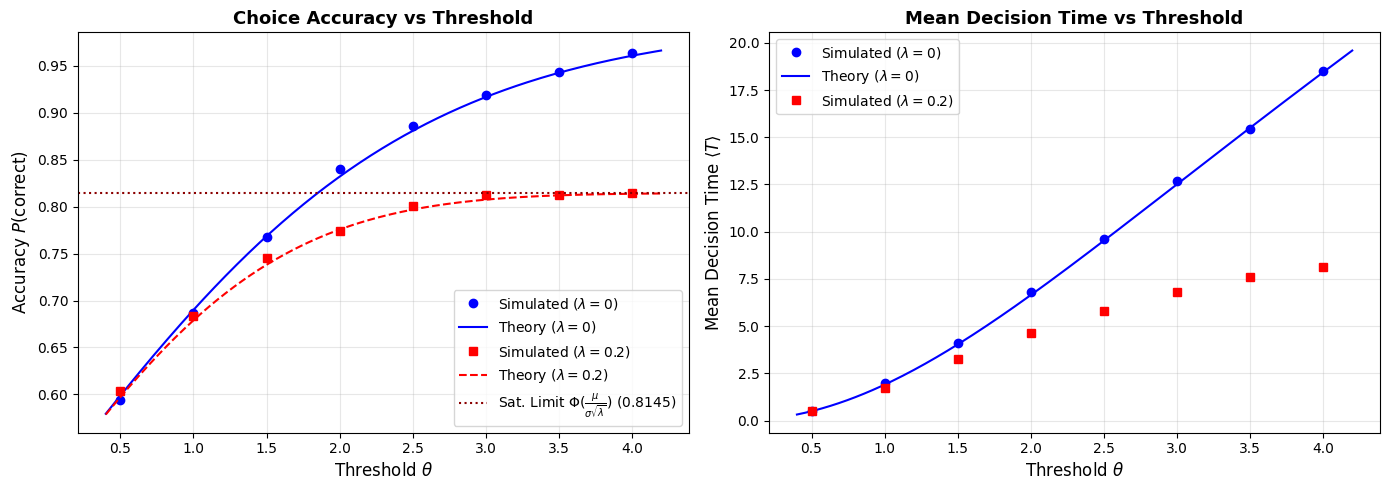


  COMPARISON AT λ = 0.2 AND θ = 4 vs PERFECT INTEGRATOR (λ = 0)   
Unstable Integrator (λ = 0.2, θ = 4.0):
  • Accuracy      : 81.48%
  • Decision Time : 8.1288 s

Perfect Integrator (λ = 0) matching accuracy (81.48%):
  • Required Threshold θ_perfect : 1.8519
  • Decision Time                : 5.8297 s
  • Time Savings / Efficiency   : Perfect integrator is 1.39x faster!


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import scipy.integrate as integrate

# Set seed for reproducibility
np.random.seed(42)

# ==========================================
# 1. Simulation Parameters
# ==========================================
mu = 0.2                   # Evidence bias
sigma = 0.5                # Noise magnitude
I0 = 5.0                   # Baseline common input
dt = 0.002                 # Euler-Maruyama integration time step
num_trials = 10000         # 10^4 trials per threshold
theta_list = np.arange(0.5, 4.5, 0.5)  # Thresholds: {0.5, 1, 1.5, ..., 4}
lambda_list = [0.0, 0.2]   # Integrator regimes: Perfect (0) and Unstable (0.2)

# Preallocate result dictionaries
sim_accuracy = {lam: [] for lam in lambda_list}
sim_decision_time = {lam: [] for lam in lambda_list}

print("Starting Euler-Maruyama Simulations...\n")

# ==========================================
# 2. Vectorized Euler-Maruyama Simulation
# ==========================================
for lam in lambda_list:
    ws = (1.0 + lam) / 2.0  # Self-excitation weight
    wc = ws                 # Mutual inhibition weight

    for theta in theta_list:
        # Initialize 10,000 parallel trials at r1 = r2 = I0
        r1 = np.full(num_trials, I0)
        r2 = np.full(num_trials, I0)

        active = np.ones(num_trials, dtype=bool)
        choice = np.zeros(num_trials)       # +1 for population 1, -1 for population 2
        decision_time = np.zeros(num_trials)

        t = 0.0
        sqrt_dt = np.sqrt(dt)

        # Integrate until all trials hit threshold |r1 - r2| >= theta
        while np.any(active):
            t += dt

            # Generate independent Gaussian noise terms for active trials
            num_active = np.sum(active)
            xi1 = np.random.normal(0, 1, size=num_active)
            xi2 = np.random.normal(0, 1, size=num_active)

            # Euler-Maruyama updates for r1 and r2
            dr1 = (-r1[active] + ws * r1[active] - wc * r2[active] + I0 + mu / 2.0) * dt + sigma * sqrt_dt * xi1
            dr2 = (-r2[active] + ws * r2[active] - wc * r1[active] + I0 - mu / 2.0) * dt + sigma * sqrt_dt * xi2

            r1[active] += dr1
            r2[active] += dr2

            # Evaluate difference condition d = r1 - r2
            diff = r1[active] - r2[active]
            crossed = np.abs(diff) >= theta

            if np.any(crossed):
                # Indices of newly terminated trials
                active_indices = np.where(active)[0]
                finished_indices = active_indices[crossed]

                # Determine choice (1 if pop 1 wins, -1 if pop 2 wins)
                choice[finished_indices] = np.sign(diff[crossed])
                decision_time[finished_indices] = t

                # Deactivate finished trials
                active[finished_indices] = False

        # Record accuracy (fraction choosing pop 1) and mean decision time
        acc = np.mean(choice == 1)
        mean_t = np.mean(decision_time)

        sim_accuracy[lam].append(acc)
        sim_decision_time[lam].append(mean_t)

        print(f"λ = {lam:.1f}, θ = {theta:.1f} | Acc: {acc:.4f}, Mean Time: {mean_t:.4f} s")

# ==========================================
# 3. Analytical Predictions
# ==========================================
theta_fine = np.linspace(0.4, 4.2, 200)

# (b) Analytical curves for λ = 0
acc_pred_lam0 = 1.0 / (1.0 + np.exp(-mu * theta_fine / (sigma**2)))
dt_pred_lam0 = (theta_fine / mu) * np.tanh(mu * theta_fine / (2.0 * sigma**2))

# (c) Analytical choice probability for λ = 0.2
def get_accuracy_lam_02(th, lam_val=0.2):
    g = lambda y: np.exp(-(lam_val * y**2 + 2 * mu * y) / (2 * sigma**2))
    num, _ = integrate.quad(g, -th, 0)
    den, _ = integrate.quad(g, -th, th)
    return num / den

acc_pred_lam02 = [get_accuracy_lam_02(th) for th in theta_fine]

# ==========================================
# 4. Plotting Results
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
ax1.plot(theta_list, sim_accuracy[0.0], 'o', color='blue', label='Simulated ($\lambda=0$)')
ax1.plot(theta_fine, acc_pred_lam0, '-', color='blue', label='Theory ($\lambda=0$)')

ax1.plot(theta_list, sim_accuracy[0.2], 's', color='red', label='Simulated ($\lambda=0.2$)')
ax1.plot(theta_fine, acc_pred_lam02, '--', color='red', label='Theory ($\lambda=0.2$)')

# Asymptotic limit for λ = 0.2 as θ -> ∞
sat_acc_lam02 = norm.cdf(mu / (sigma * np.sqrt(0.2)))
ax1.axhline(sat_acc_lam02, color='darkred', linestyle=':', label=f'Sat. Limit $\Phi(\\frac{{\mu}}{{\sigma\sqrt{{\lambda}}}})$ ({sat_acc_lam02:.4f})')

ax1.set_xlabel('Threshold $\\theta$', fontsize=12)
ax1.set_ylabel('Accuracy $P(\\text{correct})$', fontsize=12)
ax1.set_title('Choice Accuracy vs Threshold', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='lower right')

# --- Plot 2: Decision Time ---
ax2.plot(theta_list, sim_decision_time[0.0], 'o', color='blue', label='Simulated ($\lambda=0$)')
ax2.plot(theta_fine, dt_pred_lam0, '-', color='blue', label='Theory ($\lambda=0$)')

ax2.plot(theta_list, sim_decision_time[0.2], 's', color='red', label='Simulated ($\lambda=0.2$)')

ax2.set_xlabel('Threshold $\\theta$', fontsize=12)
ax2.set_ylabel('Mean Decision Time $\\langle T \\rangle$', fontsize=12)
ax2.set_title('Mean Decision Time vs Threshold', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

# ==========================================
# 5. Comparison at λ = 0.2 and θ = 4
# ==========================================
print("\n=================================================================")
print("  COMPARISON AT λ = 0.2 AND θ = 4 vs PERFECT INTEGRATOR (λ = 0)   ")
print("=================================================================")

# Performance of unstable integrator at λ = 0.2, θ = 4
acc_unstable = sim_accuracy[0.2][-1]
time_unstable = sim_decision_time[0.2][-1]

# Find equivalent threshold θ_perfect for perfect integrator (λ = 0) giving same accuracy:
# P_correct = 1 / (1 + exp(-mu * theta / sigma^2)) => theta = -(sigma^2 / mu) * ln(1/P - 1)
theta_perfect_equivalent = -(sigma**2 / mu) * np.log((1.0 / acc_unstable) - 1.0)
time_perfect_equivalent = (theta_perfect_equivalent / mu) * np.tanh(mu * theta_perfect_equivalent / (2.0 * sigma**2))

print(f"Unstable Integrator (λ = 0.2, θ = 4.0):")
print(f"  • Accuracy      : {acc_unstable * 100:.2f}%")
print(f"  • Decision Time : {time_unstable:.4f} s")
print(f"\nPerfect Integrator (λ = 0) matching accuracy ({acc_unstable * 100:.2f}%):")
print(f"  • Required Threshold θ_perfect : {theta_perfect_equivalent:.4f}")
print(f"  • Decision Time                : {time_perfect_equivalent:.4f} s")
print(f"  • Time Savings / Efficiency   : Perfect integrator is {time_unstable / time_perfect_equivalent:.2f}x faster!")

Starting Hopfield Network Simulation (N = 500)...

Alpha (α)  | Unstable (Sim)   | Unstable (Theory)  | Mean Overlap ⟨m⟩
--------------------------------------------------------------------
0.02       | 0.0000           | 0.0000             | 1.0000          
0.06       | 0.0000           | 0.0000             | 1.0000          
0.10       | 0.0008           | 0.0008             | 0.9944          
0.14       | 0.0030           | 0.0038             | 0.8068          
0.18       | 0.0081           | 0.0092             | 0.5512          
0.22       | 0.0157           | 0.0165             | 0.3396          
0.26       | 0.0239           | 0.0249             | 0.3992          
0.30       | 0.0355           | 0.0339             | 0.3232          
0.34       | 0.0443           | 0.0432             | 0.3056          
0.38       | 0.0529           | 0.0524             | 0.3320          
0.42       | 0.0628           | 0.0614             | 0.2816          
0.46       | 0.0697           | 0.0702  

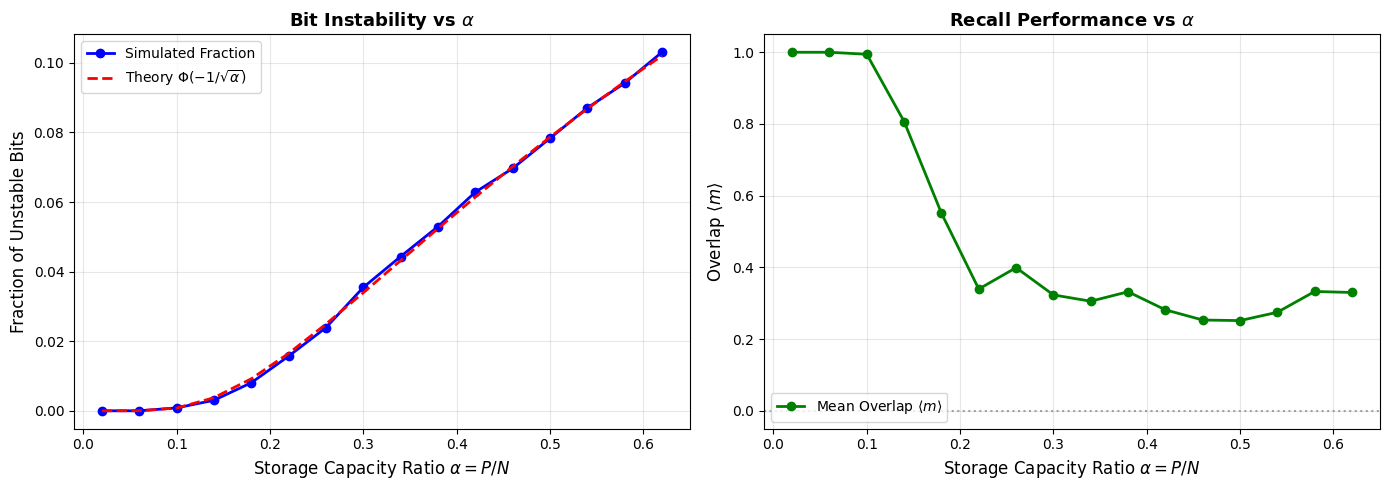


             RECALL BREAKDOWN ANALYSIS SUMMARY                   
• Low Alpha (α ≲ 0.14): Mean overlap remains near 1.0, indicating
  robust memory retrieval where stored patterns act as stable attractors.
• Critical Capacity Point (α_c ≈ 0.14 - 0.18): Crosstalk noise
  overwhelms the signal, causing successful recall to break down rapidly.
• High Alpha (α ≳ 0.2): Overlap drops toward zero (or spurious/mixed
  states), meaning the network loses the capacity to retrieve memories.


In [4]:
#problem 3c
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Set seed for reproducibility
np.random.seed(42)

# ==========================================
# 1. Simulation Parameters
# ==========================================
N = 500                                      # Number of neurons
alpha_list = np.arange(0.02, 0.64, 0.04)     # Alpha values: 0.02, 0.06, ..., 0.62
num_cues_per_alpha = 10                      # 10 cues per alpha for recall test[cite: 3]
flip_fraction = 0.10                         # 10% of bits flipped for cue[cite: 3]

unstable_fractions_sim = []
unstable_fractions_theory = []
mean_overlaps = []

print(f"Starting Hopfield Network Simulation (N = {N})...\n")
print(f"{'Alpha (α)':<10} | {'Unstable (Sim)':<16} | {'Unstable (Theory)':<18} | {'Mean Overlap ⟨m⟩':<16}")
print("-" * 68)

# ==========================================
# 2. Main Simulation Loop over α
# ==========================================
for alpha in alpha_list:
    P = int(round(alpha * N))                 # Number of stored patterns[cite: 3]

    # Draw P random patterns of size N: entries ±1 with probability 1/2[cite: 3]
    X = np.random.choice([-1, 1], size=(N, P))

    # Construct Hebbian weight matrix W (W_ii = 0)[cite: 3]
    W = (X @ X.T) / N
    np.fill_diagonal(W, 0.0)

    # --- Part A: Measure fraction of unstable bits ---
    # For every pattern mu and every bit i, compute local field h_i^\mu = sum_j W_ij xi_j^\mu[cite: 3]
    # In matrix form for all patterns: H = W @ X (N x P matrix)
    H = W @ X
    # Stability condition: xi_i^\mu * h_i^\mu < 0 means unstable[cite: 3]
    stability = X * H
    unstable_bits = np.sum(stability < 0)
    total_bits = N * P
    frac_unstable = unstable_bits / total_bits
    unstable_fractions_sim.append(frac_unstable)

    # Theoretical prediction: Φ(-1 / sqrt(alpha))[cite: 3]
    theory_val = norm.cdf(-1.0 / np.sqrt(alpha))
    unstable_fractions_theory.append(theory_val)

    # --- Part B: Test Recall over 10 cues ---
    overlaps_for_alpha = []

    for cue_idx in range(num_cues_per_alpha):
        # Pick a target pattern to test (e.g., pattern 0)
        target_pattern = X[:, cue_idx % P].copy()

        # Corrupt 10% of its bits by flipping them[cite: 3]
        s = target_pattern.copy()
        num_to_flip = int(flip_fraction * N)
        flip_indices = np.random.choice(N, size=num_to_flip, replace=False)
        s[flip_indices] *= -1

        # Asynchronous updates in random order until a full sweep changes nothing[cite: 3]
        max_sweeps = 100
        for sweep in range(max_sweeps):
            s_old = s.copy()
            # Random update order (asynchronous)[cite: 3]
            update_order = np.random.permutation(N)

            for i in update_order:
                # Local field h_i = sum_j W_ij s_j[cite: 3]
                hi = np.dot(W[i], s)
                # s_i <- sgn(h_i) with sgn(0) = 1[cite: 3]
                s[i] = 1 if hi >= 0 else -1

            # Check convergence: if a full sweep changes nothing, stop[cite: 3]
            if np.array_equal(s, s_old):
                break

        # Record final overlap m = (1/N) * (xi^mu · s)[cite: 3]
        m = np.dot(target_pattern, s) / N
        overlaps_for_alpha.append(m)

    mean_m = np.mean(overlaps_for_alpha)
    mean_overlaps.append(mean_m)

    print(f"{alpha:<10.2f} | {frac_unstable:<16.4f} | {theory_val:<18.4f} | {mean_m:<16.4f}")

# ==========================================
# 3. Plotting Results
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Fraction of Unstable Bits vs Alpha ---
ax1.plot(alpha_list, unstable_fractions_sim, 'bo-', label='Simulated Fraction', lw=2)
ax1.plot(alpha_list, unstable_fractions_theory, 'r--', label='Theory $\\Phi(-1/\\sqrt{\\alpha})$', lw=2)
ax1.set_xlabel('Storage Capacity Ratio $\\alpha = P/N$', fontsize=12)
ax1.set_ylabel('Fraction of Unstable Bits', fontsize=12)
ax1.set_title('Bit Instability vs $\\alpha$', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper left')

# --- Plot 2: Mean Overlap vs Alpha (Recall Test) ---
ax2.plot(alpha_list, mean_overlaps, 'go-', label='Mean Overlap $\\langle m \\rangle$', lw=2)
ax2.axhline(0, color='gray', linestyle=':', alpha=0.7)
ax2.set_xlabel('Storage Capacity Ratio $\\alpha = P/N$', fontsize=12)
ax2.set_ylabel('Overlap $\\langle m \\rangle$', fontsize=12)
ax2.set_title('Recall Performance vs $\\alpha$', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='lower left')

plt.tight_layout()
plt.show()

# ==========================================
# 4. Break Down Analysis
# ==========================================
print("\n=================================================================")
print("             RECALL BREAKDOWN ANALYSIS SUMMARY                   ")
print("=================================================================")
print("• Low Alpha (α ≲ 0.14): Mean overlap remains near 1.0, indicating")
print("  robust memory retrieval where stored patterns act as stable attractors.")
print("• Critical Capacity Point (α_c ≈ 0.14 - 0.18): Crosstalk noise")
print("  overwhelms the signal, causing successful recall to break down rapidly.")
print("• High Alpha (α ≳ 0.2): Overlap drops toward zero (or spurious/mixed")
print("  states), meaning the network loses the capacity to retrieve memories.")